# 03 · Features → `features.csv`

One row per usable lab sample, with:

- **satellite** (Sentinel-2 L2A, Microsoft Planetary Computer): water-colour indices from the closest clear image within ±5 days;
- **weather** (NASA POWER): heat, rain, wind and sunlight in the days before the sample;
- **water stored** (COGERH Table 2): volume % and its change since the previous campaign;
- **season**: month (as sine and cosine) and a rainy-season flag;
- **last lab result** (for the persistence baseline): the reservoir's previous campaign.

Nothing here looks at the label of the sample itself except `y`.

**Region: the Jaguaribe system** (Alto, Médio and Baixo Jaguaribe, Banabuiú, Salgado; 65 reservoirs). Each image read costs about 3.5 MB and our connection downloads about 0.5 MB/s, so the whole state would not fit in the hackathon. One region tied to real users (the Jaguaribe Valley cities) is also what the Climate track asks for.

In [1]:
import sys
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

sys.path.insert(0, str(Path.cwd().parent / "src"))
from common import PROCESSED, RAW, OUTPUTS, CYANO_THRESHOLD
from satellite import CRS, features_for_sample, MAX_GAP_DAYS, MIN_WATER_PX
from weather import grid_cell, fetch_cell, window_features

pd.set_option("display.width", 200, "display.max_columns", 40)
samples = pd.read_csv(PROCESSED / "samples.csv", parse_dates=["date"])
res = gpd.read_file(PROCESSED / "reservoirs.geojson").set_index("reservoir")
jag = res.index[res["jaguaribe_system"]]
lab = samples[samples["usable"] & samples["reservoir"].isin(jag)].copy()
print(len(lab), "usable samples in the Jaguaribe system")

1479 usable samples in the Jaguaribe system


## Satellite features

For each sample: search Sentinel-2 images within ±5 days of the lab date, try them from the closest, and keep the first one with at least 30 clean water pixels in the AOI. Water pixel = scene classification says water **and** MNDWI > 0, then the mask is eroded by 2 pixels to drop shoreline pixels. Values are medians over those pixels.

Features (from the median reflectances of bands B03, B04, B05, B11):
- **NDCI** = (B05 − B04) / (B05 + B04): chlorophyll absorbs red light and raises red-edge reflectance (Mishra & Mishra, 2012).
- **NDTI** = (B04 − B03) / (B04 + B03): turbidity.
- **MNDWI** = (B03 − B11) / (B03 + B11): how "clean" the water signal is.
- **water_frac**: share of the clear AOI that is water (shrinks when the reservoir dries).

We read only these four bands (plus the scene classification) because every band costs a download. The three-band index and MCI from the original plan need B06, so they were dropped.

Results are cached per sample in `data/processed/s2_cache/` (extraction took about 2.5 hours; `src/run_s2.py`).

In [2]:
aoi_utm = res.to_crs(CRS).geometry
keys = lab[["reservoir", "date"]].drop_duplicates()

def job(r):
    return {"reservoir": r.reservoir, "date": r.date,
            **features_for_sample(r.reservoir, r.date, aoi_utm[r.reservoir], res.geometry[r.reservoir].bounds,
                                  PROCESSED / "s2_cache", cache_only=True)}

with ThreadPoolExecutor(8) as ex:
    s2 = pd.DataFrame(list(ex.map(job, keys.itertuples())))
print(s2["status"].value_counts().to_string())

status
not extracted yet                         1340
no image with >= 30 clean water pixels      75
ok                                          50
no image within +-5 days                    14


In [3]:
ok = s2[s2["status"] == "ok"].copy()
print("day gap (days):", ok["day_gap"].value_counts().sort_index().to_dict())
print("clean water pixels: median", int(ok["n_water_px"].median()), " min", int(ok["n_water_px"].min()))
ok["after_2022"] = pd.to_datetime(ok["img_date"]) >= "2022-01-25"
print("\nprocessing-baseline offset check (median red reflectance of water, after correction):")
print(ok.groupby("after_2022")["B04"].median().round(4).to_string())

day gap (days): {0.0: 3, 1.0: 19, 2.0: 12, 3.0: 7, 4.0: 5, 5.0: 4}
clean water pixels: median 348  min 34

processing-baseline offset check (median red reflectance of water, after correction):
after_2022
False    0.0294
True     0.0306


## Does the satellite see what the lab measures?

Before any model: rank correlation (Spearman) between each index and the lab values. NDCI should rise with chlorophyll-a. This is the physical basis of the whole project.

     index  rho_vs_chla  rho_vs_cyano
      NDCI        0.717         0.420
      NDTI       -0.226        -0.231
     MNDWI        0.346         0.033
water_frac        0.235         0.167


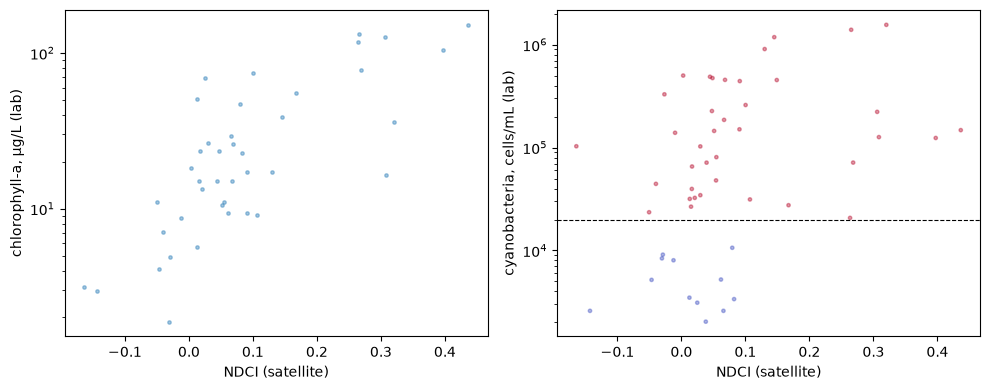

In [4]:
chk = lab.merge(ok, on=["reservoir", "date"])
rows = []
for idx in ["NDCI", "NDTI", "MNDWI", "water_frac"]:
    r1 = spearmanr(chk[idx], chk["chla"], nan_policy="omit")[0]
    r2 = spearmanr(chk[idx], chk["cyano"], nan_policy="omit")[0]
    rows.append({"index": idx, "rho_vs_chla": round(r1, 3), "rho_vs_cyano": round(r2, 3)})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(chk["NDCI"], chk["chla"], s=6, alpha=0.4)
ax[0].set_yscale("log"); ax[0].set_xlabel("NDCI (satellite)"); ax[0].set_ylabel("chlorophyll-a, µg/L (lab)")
ax[1].scatter(chk["NDCI"], chk["cyano"], s=6, alpha=0.4, c=(chk["cyano"] > CYANO_THRESHOLD), cmap="coolwarm")
ax[1].axhline(CYANO_THRESHOLD, color="k", lw=0.8, ls="--")
ax[1].set_yscale("log"); ax[1].set_xlabel("NDCI (satellite)"); ax[1].set_ylabel("cyanobacteria, cells/mL (lab)")
plt.tight_layout(); plt.savefig(OUTPUTS / "ndci_vs_lab.png", dpi=110); plt.show()

## Weather features

NASA POWER daily data, one series per ~50 km grid cell (cached in `data/raw/power/`). Windows end the day before the sample.

In [5]:
res["cell"] = [grid_cell(a, b) for a, b in zip(res["lat"], res["lon"])]
series = {c: fetch_cell(*c, RAW / "power") for c in res["cell"].unique()}
w = pd.DataFrame([{"reservoir": r.reservoir, "date": r.date, **window_features(series[res.loc[r.reservoir, "cell"]], r.date)}
                  for r in keys.itertuples()])
print(len(series), "weather cells")
w.describe().round(2)

40 weather cells


,date,tmax_7d,tmax_30d,rain_30d,rain_90d,wind_7d,sw_7d
count,1479,1479.00,1479.00,1479.00,1479.00,1479.00,1479.00
mean,2020-01-24 21:22:16.308316416,34.39,34.46,55.28,156.59,3.03,21.30
min,2016-01-13 00:00:00,26.98,27.70,0.00,0.15,1.28,13.98
25%,2018-02-19 12:00:00,32.53,32.71,8.59,44.45,2.33,19.48
50%,2019-10-24 00:00:00,34.74,34.56,33.93,116.73,2.96,21.30
75%,2021-08-16 12:00:00,36.48,36.44,84.28,235.76,3.65,23.32
max,2025-03-12 00:00:00,39.71,39.20,325.07,590.51,5.48,27.90
std,NaN,2.78,2.56,59.19,137.67,0.87,2.59


## Last lab result (persistence) and water stored

For each sample, the reservoir's **previous** usable lab result from an earlier campaign. This is what a technician knows today, and it is built before any train/test split, from earlier dates only. `volume_change` is the change in volume % since that previous campaign.

In [6]:
hist = samples[samples["usable"]].sort_values("date")[["reservoir", "campaign", "date", "cyano", "volume_pct"]]
hist["prev_campaign"] = hist.groupby("reservoir")["campaign"].shift()
hist["prev_date"] = hist.groupby("reservoir")["date"].shift()
hist["prev_cyano"] = hist.groupby("reservoir")["cyano"].shift()
hist["prev_volume"] = hist.groupby("reservoir")["volume_pct"].shift()
hist["prev_class"] = (hist["prev_cyano"] > CYANO_THRESHOLD).astype(float).where(hist["prev_cyano"].notna())
hist["prev_gap_days"] = (hist["date"] - hist["prev_date"]).dt.days
hist["volume_change"] = hist["volume_pct"] - hist["prev_volume"]
assert (hist["prev_date"].dropna() < hist.loc[hist["prev_date"].notna(), "date"]).all()
print("previous result available for", int(hist["prev_cyano"].notna().sum()), "of", len(hist), "samples")
print("gap to previous result (days):", hist["prev_gap_days"].describe().round(0).to_dict())

previous result available for 3472 of 3628 samples
gap to previous result (days): {'count': 3472.0, 'mean': 137.0, 'std': 127.0, 'min': 23.0, '25%': 90.0, '50%': 92.0, '75%': 120.0, 'max': 2275.0}


## Assemble and save

In [7]:
feat = (lab[["reservoir", "date", "campaign", "cyano", "chla", "volume_pct"]]
        .merge(res[["basin", "jaguaribe_system"]], left_on="reservoir", right_index=True)
        .merge(ok.drop(columns=["status", "after_2022"]), on=["reservoir", "date"])
        .merge(w, on=["reservoir", "date"], how="left")
        .merge(hist[["reservoir", "date", "prev_campaign", "prev_cyano", "prev_class", "prev_gap_days", "volume_change"]],
               on=["reservoir", "date"], how="left"))
feat["y"] = (feat["cyano"] > CYANO_THRESHOLD).astype(int)
m = feat["date"].dt.month
feat["month_sin"], feat["month_cos"] = np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12)
feat["rainy_season"] = m.between(2, 5).astype(int)
feat = feat.sort_values(["date", "reservoir"]).reset_index(drop=True)
feat.to_csv(PROCESSED / "features.csv", index=False, date_format="%Y-%m-%d")
print(feat.shape, "->", PROCESSED / "features.csv")
print("positive share:", round(feat["y"].mean(), 3))
feat.groupby("campaign").agg(n=("y", "size"), positives=("y", "sum")).T

(50, 41) -> C:\Users\Filipe\alerta-acude\data\processed\features.csv
positive share: 0.76


campaign,2016-08,2017-05,2017-08,2018-05,2018-08,2018-11,2019-02,2019-05,2019-08,2019-11,2020-02,2020-11,2021-02,2021-05,2021-08,2021-11,2022-02,2022-11,2024-02,2024-08,2025-02
n,1,2,3,4,2,3,2,3,3,1,2,2,2,5,3,1,2,1,2,4,2
positives,1,2,3,1,1,0,1,3,1,1,2,2,2,4,3,1,2,1,2,3,2
